In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/hojjatk/mnist-dataset


In [2]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import random

# =========================================================
# 1. Parametri
# =========================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE_AE = 128
BATCH_SIZE_SUM = 128

LATENT_DIM = 16
EPOCHS_AE = 20
EPOCHS_SUM = 20

LR_AE = 1e-3
LR_SUM = 1e-3

IMAGE_SIZE = 28
NUM_SUM_CLASSES = 19   # somme da 0 a 18

print("DEVICE:", DEVICE)


# =========================================================
# 2. Dataset MNIST
# =========================================================
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader_ae = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE_AE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader_ae = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE_AE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


# =========================================================
# 3. Spherical Autoencoder
#    L'encoder produce un embedding latente che viene
#    normalizzato sulla sfera unitaria.
# =========================================================
class SphericalAutoencoder(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()

        # Encoder
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),   # 28 -> 14
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 14 -> 7
            nn.ReLU(inplace=True)
        )

        self.fc_enc = nn.Linear(64 * 7 * 7, latent_dim)

        # Decoder
        self.fc_dec = nn.Linear(latent_dim, 64 * 7 * 7)

        self.decoder_deconv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),  # 7 -> 14
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),   # 14 -> 28
            nn.Sigmoid()
        )

    def encode_raw(self, x):
        h = self.encoder_conv(x)
        h = h.view(h.size(0), -1)
        z_raw = self.fc_enc(h)
        return z_raw

    def encode(self, x):
        z_raw = self.encode_raw(x)
        z = F.normalize(z_raw, p=2, dim=1)
        return z

    def decode(self, z):
        h = self.fc_dec(z)
        h = h.view(z.size(0), 64, 7, 7)
        x_hat = self.decoder_deconv(h)
        return x_hat

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat, z


# =========================================================
# 4. Training Autoencoder
# =========================================================
def train_autoencoder(model, train_loader, test_loader, epochs, lr):
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_loss_history = []
    test_loss_history = []

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0

        for images, _ in train_loader:
            images = images.to(DEVICE)

            optimizer.zero_grad()

            recon, z = model(images)
            loss_mse = F.mse_loss(recon, images, reduction="mean")
            loss_l1 = F.l1_loss(recon, images, reduction="mean")
            loss = loss_mse + 0.1 * loss_l1

            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / len(train_loader)
        train_loss_history.append(avg_train_loss)

        model.eval()
        total_test_loss = 0.0

        with torch.no_grad():
            for images, _ in test_loader:
                images = images.to(DEVICE)

                recon, z = model(images)
                loss_mse = F.mse_loss(recon, images, reduction="mean")
                loss_l1 = F.l1_loss(recon, images, reduction="mean")
                loss = loss_mse + 0.1 * loss_l1

                total_test_loss += loss.item()

        avg_test_loss = total_test_loss / len(test_loader)
        test_loss_history.append(avg_test_loss)

        print(
            f"[AE SFERICO] Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {avg_train_loss:.6f} | "
            f"Test Loss: {avg_test_loss:.6f}"
        )

    return train_loss_history, test_loss_history


# =========================================================
# 5. Dataset delle coppie per la somma
# =========================================================
class SumPairsDataset(Dataset):
    """
    Costruisce coppie di immagini MNIST.
    Ogni elemento restituisce:
    - img1
    - img2
    - sum_label = digit1 + digit2
    """
    def __init__(self, base_dataset, n_pairs=20000):
        self.base_dataset = base_dataset
        self.n_pairs = n_pairs

    def __len__(self):
        return self.n_pairs

    def __getitem__(self, idx):
        idx1 = random.randint(0, len(self.base_dataset) - 1)
        idx2 = random.randint(0, len(self.base_dataset) - 1)

        img1, label1 = self.base_dataset[idx1]
        img2, label2 = self.base_dataset[idx2]

        sum_label = int(label1) + int(label2)

        return img1, img2, sum_label


# =========================================================
# 6. MLP per predire la somma
# =========================================================
class SumPredictorMLP(nn.Module):
    def __init__(self, input_dim=32, hidden_dim=128, num_classes=19):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(inplace=True),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(inplace=True),

            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.net(x)


# =========================================================
# 7. Training del modello per la somma
# =========================================================
def train_sum_predictor(encoder_model, predictor_model, train_loader, test_loader, epochs, lr):
    # Congeliamo l'encoder
    encoder_model.eval()
    for param in encoder_model.parameters():
        param.requires_grad = False

    optimizer = optim.Adam(predictor_model.parameters(), lr=lr)

    train_acc_history = []
    test_acc_history = []

    for epoch in range(epochs):
        predictor_model.train()
        correct = 0
        total = 0

        for img1, img2, sum_label in train_loader:
            img1 = img1.to(DEVICE)
            img2 = img2.to(DEVICE)
            sum_label = sum_label.to(DEVICE)

            with torch.no_grad():
                z1 = encoder_model.encode(img1)   # [B, 16] sulla sfera
                z2 = encoder_model.encode(img2)   # [B, 16] sulla sfera

            z_pair = torch.cat([z1, z2], dim=1)   # [B, 32]

            optimizer.zero_grad()

            logits = predictor_model(z_pair)
            loss = F.cross_entropy(logits, sum_label)

            loss.backward()
            optimizer.step()

            preds = torch.argmax(logits, dim=1)
            correct += (preds == sum_label).sum().item()
            total += sum_label.size(0)

        train_acc = correct / total
        train_acc_history.append(train_acc)

        predictor_model.eval()
        correct_test = 0
        total_test = 0

        with torch.no_grad():
            for img1, img2, sum_label in test_loader:
                img1 = img1.to(DEVICE)
                img2 = img2.to(DEVICE)
                sum_label = sum_label.to(DEVICE)

                z1 = encoder_model.encode(img1)
                z2 = encoder_model.encode(img2)

                z_pair = torch.cat([z1, z2], dim=1)
                logits = predictor_model(z_pair)

                preds = torch.argmax(logits, dim=1)
                correct_test += (preds == sum_label).sum().item()
                total_test += sum_label.size(0)

        test_acc = correct_test / total_test
        test_acc_history.append(test_acc)

        print(
            f"[SUM] Epoch {epoch+1}/{epochs} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Test Acc: {test_acc:.4f}"
        )

    return train_acc_history, test_acc_history


# =========================================================
# 8. Costruzione pair dataset
# =========================================================
sum_train_dataset = SumPairsDataset(train_dataset, n_pairs=30000)
sum_test_dataset = SumPairsDataset(test_dataset, n_pairs=5000)

sum_train_loader = DataLoader(
    sum_train_dataset,
    batch_size=BATCH_SIZE_SUM,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

sum_test_loader = DataLoader(
    sum_test_dataset,
    batch_size=BATCH_SIZE_SUM,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


# =========================================================
# 9. Training completo
# =========================================================
autoencoder = SphericalAutoencoder(latent_dim=LATENT_DIM).to(DEVICE)
sum_predictor = SumPredictorMLP(
    input_dim=LATENT_DIM * 2,
    hidden_dim=128,
    num_classes=NUM_SUM_CLASSES
).to(DEVICE)

print("\n=== Training Spherical Autoencoder ===")
ae_train_hist, ae_test_hist = train_autoencoder(
    autoencoder,
    train_loader_ae,
    test_loader_ae,
    epochs=EPOCHS_AE,
    lr=LR_AE
)

print("\n=== Training Sum Predictor ===")
sum_train_hist, sum_test_hist = train_sum_predictor(
    autoencoder,
    sum_predictor,
    sum_train_loader,
    sum_test_loader,
    epochs=EPOCHS_SUM,
    lr=LR_SUM
)


# =========================================================
# 10. Test rapido su un batch
# =========================================================
autoencoder.eval()
sum_predictor.eval()

img1, img2, sum_label = next(iter(sum_test_loader))
img1 = img1.to(DEVICE)
img2 = img2.to(DEVICE)
sum_label = sum_label.to(DEVICE)

with torch.no_grad():
    z1 = autoencoder.encode(img1)
    z2 = autoencoder.encode(img2)
    z_pair = torch.cat([z1, z2], dim=1)

    logits = sum_predictor(z_pair)
    preds = torch.argmax(logits, dim=1)

print("\nPrime 10 somme vere:", sum_label[:10].cpu().tolist())
print("Prime 10 somme predette:", preds[:10].cpu().tolist())
print("Shape di z1:", z1.shape)
print("Shape di z2:", z2.shape)
print("Shape concatenata:", z_pair.shape)


DEVICE: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 60.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.75MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.74MB/s]



=== Training Spherical Autoencoder ===
[AE SFERICO] Epoch 1/20 | Train Loss: 0.047163 | Test Loss: 0.021854
[AE SFERICO] Epoch 2/20 | Train Loss: 0.020547 | Test Loss: 0.018521
[AE SFERICO] Epoch 3/20 | Train Loss: 0.017842 | Test Loss: 0.016310
[AE SFERICO] Epoch 4/20 | Train Loss: 0.016066 | Test Loss: 0.014998
[AE SFERICO] Epoch 5/20 | Train Loss: 0.014926 | Test Loss: 0.014220
[AE SFERICO] Epoch 6/20 | Train Loss: 0.014166 | Test Loss: 0.013587
[AE SFERICO] Epoch 7/20 | Train Loss: 0.013633 | Test Loss: 0.013161
[AE SFERICO] Epoch 8/20 | Train Loss: 0.013224 | Test Loss: 0.012801
[AE SFERICO] Epoch 9/20 | Train Loss: 0.012887 | Test Loss: 0.012594
[AE SFERICO] Epoch 10/20 | Train Loss: 0.012610 | Test Loss: 0.012309
[AE SFERICO] Epoch 11/20 | Train Loss: 0.012369 | Test Loss: 0.012154
[AE SFERICO] Epoch 12/20 | Train Loss: 0.012148 | Test Loss: 0.011965
[AE SFERICO] Epoch 13/20 | Train Loss: 0.011952 | Test Loss: 0.011738
[AE SFERICO] Epoch 14/20 | Train Loss: 0.011783 | Test Loss

In [3]:
import matplotlib.pyplot as plt

# =========================================================
# 11. Estrazione di tutti gli embedding latenti del dataset
# =========================================================
def extract_latent_database(autoencoder, dataset, device):
    autoencoder.eval()

    all_images = []
    all_labels = []
    all_latents = []

    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            z = autoencoder.encode(images)

            all_images.append(images.cpu())
            all_labels.append(labels.cpu())
            all_latents.append(z.cpu())

    all_images = torch.cat(all_images, dim=0)    # [N, 1, 28, 28]
    all_labels = torch.cat(all_labels, dim=0)    # [N]
    all_latents = torch.cat(all_latents, dim=0)  # [N, 16]

    return all_images, all_labels, all_latents


# =========================================================
# 12. Estrazione di un campione di una cifra specifica
# =========================================================
def get_one_sample_of_digit(dataset, digit):
    indices = [i for i, (_, label) in enumerate(dataset) if int(label) == digit]
    idx = random.choice(indices)
    image, label = dataset[idx]
    return image, label, idx


# =========================================================
# 13. Ricerca dei candidati nel latent space dato
#     un numero noto e una somma target
# =========================================================
def find_candidates_for_sum(
    autoencoder,
    sum_predictor,
    known_image,
    target_sum,
    latent_database,
    label_database,
    image_database,
    top_k=10
):
    autoencoder.eval()
    sum_predictor.eval()

    with torch.no_grad():
        # Embedding latente della cifra nota
        known_image = known_image.unsqueeze(0).to(DEVICE)   # [1, 1, 28, 28]
        z_known = autoencoder.encode(known_image)           # [1, 16]

        # Ripetiamo z_known per abbinarlo a tutto il database latente
        z_known_repeat = z_known.repeat(latent_database.size(0), 1).cpu()

        # Concatenazione [z_known ; z_candidate]
        z_pairs = torch.cat([z_known_repeat, latent_database], dim=1).to(DEVICE)  # [N, 32]

        logits = sum_predictor(z_pairs)
        probs = F.softmax(logits, dim=1)

        # Probabilità associata alla somma target
        target_probs = probs[:, target_sum]   # [N]

        # Selezioniamo i top_k candidati con probabilità più alta
        top_values, top_indices = torch.topk(target_probs, k=top_k)

    results = []
    for rank, idx in enumerate(top_indices.cpu().tolist()):
        results.append({
            "rank": rank + 1,
            "dataset_index": idx,
            "pred_prob_target_sum": float(top_values[rank].cpu().item()),
            "candidate_label": int(label_database[idx].item()),
            "candidate_image": image_database[idx],
            "candidate_latent": latent_database[idx]
        })

    return results


# =========================================================
# 14. Visualizzazione dei risultati della ricerca
# =========================================================
def show_sum_search_results(known_image, known_digit, target_sum, results):
    n = len(results)

    plt.figure(figsize=(2 * (n + 1), 4))

    # Prima colonna: cifra nota
    plt.subplot(2, n + 1, 1)
    plt.imshow(known_image.squeeze(0), cmap="gray")
    plt.axis("off")
    plt.title(f"Known\nDigit={known_digit}")

    plt.subplot(2, n + 1, n + 2)
    plt.axis("off")
    plt.text(
        0.5, 0.5,
        f"Target sum = {target_sum}",
        ha="center", va="center", fontsize=12
    )

    # Colonne successive: candidati trovati
    for i, item in enumerate(results):
        plt.subplot(2, n + 1, i + 2)
        plt.imshow(item["candidate_image"].squeeze(0), cmap="gray")
        plt.axis("off")
        plt.title(f"Rank {item['rank']}")

        plt.subplot(2, n + 1, n + 3 + i)
        plt.axis("off")
        txt = (
            f"Digit={item['candidate_label']}\n"
            f"P(sum={target_sum})={item['pred_prob_target_sum']:.3f}"
        )
        plt.text(0.5, 0.5, txt, ha="center", va="center", fontsize=10)

    plt.tight_layout()
    plt.show()


# =========================================================
# 15. Costruzione del database latente
# =========================================================
db_images, db_labels, db_latents = extract_latent_database(
    autoencoder,
    test_dataset,
    DEVICE
)

print("Latent database shape:", db_latents.shape)
print("Image database shape:", db_images.shape)
print("Label database shape:", db_labels.shape)




Latent database shape: torch.Size([10000, 16])
Image database shape: torch.Size([10000, 1, 28, 28])
Label database shape: torch.Size([10000])


In [4]:
# =========================================================
# 16. Esempio: cifra nota = 5, somma target = 11
# =========================================================
known_digit = 6
target_sum = 11

Known digit: 6, target sum: 11
Rank 1 | Candidate digit: 5 | P(sum=11): 0.9981
Rank 2 | Candidate digit: 5 | P(sum=11): 0.9981
Rank 3 | Candidate digit: 5 | P(sum=11): 0.9980
Rank 4 | Candidate digit: 5 | P(sum=11): 0.9980
Rank 5 | Candidate digit: 5 | P(sum=11): 0.9979
Rank 6 | Candidate digit: 5 | P(sum=11): 0.9978
Rank 7 | Candidate digit: 5 | P(sum=11): 0.9978
Rank 8 | Candidate digit: 5 | P(sum=11): 0.9973


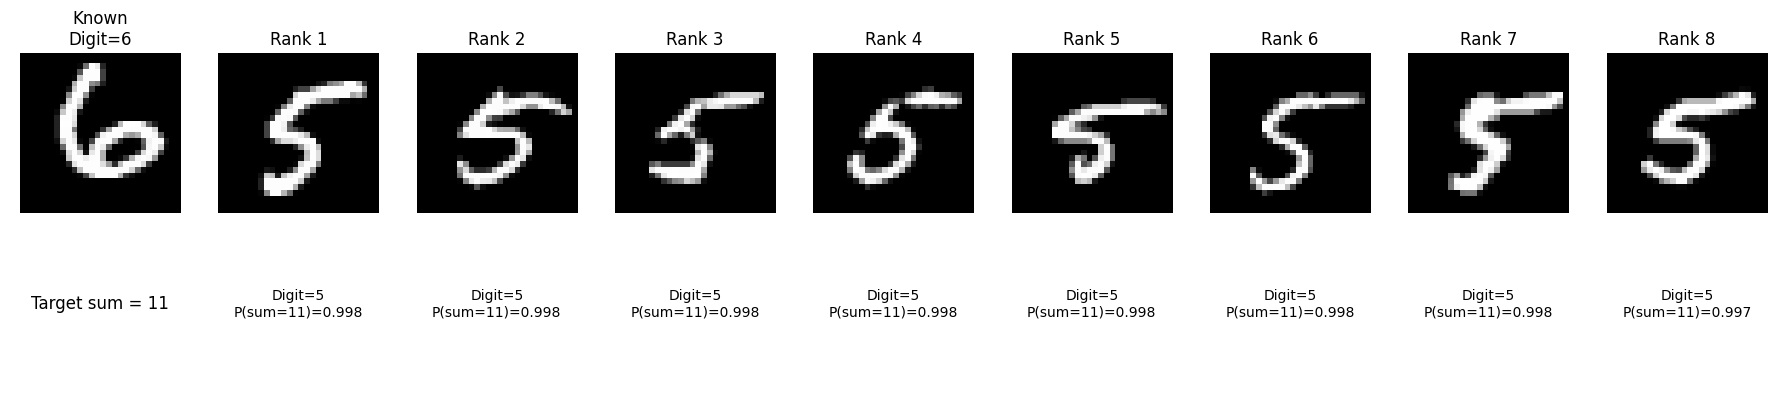

In [5]:


known_image, known_label, known_idx = get_one_sample_of_digit(test_dataset, known_digit)

results = find_candidates_for_sum(
    autoencoder=autoencoder,
    sum_predictor=sum_predictor,
    known_image=known_image,
    target_sum=target_sum,
    latent_database=db_latents,
    label_database=db_labels,
    image_database=db_images,
    top_k=8
)

print(f"Known digit: {known_label}, target sum: {target_sum}")
for item in results:
    print(
        f"Rank {item['rank']} | "
        f"Candidate digit: {item['candidate_label']} | "
        f"P(sum={target_sum}): {item['pred_prob_target_sum']:.4f}"
    )

show_sum_search_results(
    known_image=known_image,
    known_digit=known_digit,
    target_sum=target_sum,
    results=results
)

In [6]:
import math
import matplotlib.pyplot as plt

# =========================================================
# 17. Funzione energia per simulated annealing
# =========================================================
def compute_sum_energy(sum_predictor, z_known, z_candidate, target_sum):
    """
    Energia = -log P(somma = target_sum | [z_known ; z_candidate])
    Più l'energia è bassa, meglio è.
    """
    sum_predictor.eval()

    with torch.no_grad():
        z_pair = torch.cat([z_known, z_candidate], dim=1)   # [1, 32]
        logits = sum_predictor(z_pair)
        probs = F.softmax(logits, dim=1)

        target_prob = probs[0, target_sum].item()
        target_prob = max(target_prob, 1e-12)  # protezione numerica

        energy = -math.log(target_prob)

    return energy, target_prob


# =========================================================
# 18. Simulated annealing nel latent space
# =========================================================
def simulated_annealing_search(
    autoencoder,
    sum_predictor,
    known_image,
    target_sum,
    latent_dim=16,
    n_steps=2000,
    init_temp=1.0,
    final_temp=1e-3,
    step_std=0.1,
    spherical=False,
    verbose=True
):
    """
    Cerca un vettore latente z_unknown che, concatenato con z_known,
    renda massima la probabilità della somma target.

    Se spherical=False:
        ricerca in spazio euclideo normale

    Se spherical=True:
        dopo ogni perturbazione il vettore viene rinormalizzato sulla sfera
    """
    autoencoder.eval()
    sum_predictor.eval()

    with torch.no_grad():
        known_image = known_image.unsqueeze(0).to(DEVICE)     # [1, 1, 28, 28]
        z_known = autoencoder.encode(known_image)             # [1, latent_dim]

    # Inizializzazione casuale del candidato
    z_current = torch.randn(1, latent_dim, device=DEVICE)

    if spherical:
        z_current = F.normalize(z_current, p=2, dim=1)

    current_energy, current_prob = compute_sum_energy(
        sum_predictor,
        z_known,
        z_current,
        target_sum
    )

    best_z = z_current.clone()
    best_energy = current_energy
    best_prob = current_prob

    energy_history = [current_energy]
    prob_history = [current_prob]

    for step in range(n_steps):
        # Temperatura con schedule esponenziale
        t_ratio = step / max(n_steps - 1, 1)
        temperature = init_temp * ((final_temp / init_temp) ** t_ratio)

        # Proposta: perturbazione casuale
        z_proposal = z_current + step_std * torch.randn_like(z_current)

        if spherical:
            z_proposal = F.normalize(z_proposal, p=2, dim=1)

        proposal_energy, proposal_prob = compute_sum_energy(
            sum_predictor,
            z_known,
            z_proposal,
            target_sum
        )

        delta = proposal_energy - current_energy

        # Regola di accettazione del simulated annealing
        if delta < 0:
            accept = True
        else:
            accept_prob = math.exp(-delta / max(temperature, 1e-12))
            accept = (random.random() < accept_prob)

        if accept:
            z_current = z_proposal
            current_energy = proposal_energy
            current_prob = proposal_prob

        # Aggiornamento best
        if current_energy < best_energy:
            best_z = z_current.clone()
            best_energy = current_energy
            best_prob = current_prob

        energy_history.append(current_energy)
        prob_history.append(current_prob)

        if verbose and (step + 1) % 200 == 0:
            print(
                f"Step {step+1}/{n_steps} | "
                f"Temp: {temperature:.6f} | "
                f"Current Energy: {current_energy:.4f} | "
                f"Current P(target): {current_prob:.4f} | "
                f"Best P(target): {best_prob:.4f}"
            )

    return {
        "z_known": z_known.detach().cpu(),
        "best_z": best_z.detach().cpu(),
        "best_energy": best_energy,
        "best_prob": best_prob,
        "energy_history": energy_history,
        "prob_history": prob_history
    }


# =========================================================
# 19. Decodifica del latent trovato
# =========================================================
def decode_latent(autoencoder, z):
    autoencoder.eval()
    with torch.no_grad():
        z = z.to(DEVICE)
        recon = autoencoder.decode(z).cpu()
    return recon


# =========================================================
# 20. Visualizzazione del risultato del simulated annealing
# =========================================================
def show_sa_result(known_image, known_digit, target_sum, sa_result, autoencoder):
    best_z = sa_result["best_z"]
    best_prob = sa_result["best_prob"]

    generated = decode_latent(autoencoder, best_z)[0]

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(known_image.squeeze(0), cmap="gray")
    plt.axis("off")
    plt.title(f"Cifra nota\n{known_digit}")

    plt.subplot(1, 3, 2)
    plt.imshow(generated.squeeze(0), cmap="gray")
    plt.axis("off")
    plt.title(f"z trovato\nP(sum={target_sum})={best_prob:.3f}")

    plt.subplot(1, 3, 3)
    plt.plot(sa_result["prob_history"])
    plt.xlabel("Step")
    plt.ylabel(f"P(sum={target_sum})")
    plt.title("Evoluzione della probabilità")
    plt.grid(True)

    plt.tight_layout()
    plt.show()

with simulated annealing

In [14]:

known_digit = 5
target_sum = 11

In [8]:

# =========================================================
# Energia con regolarizzazione rispetto al latent database
# Versione sferica: si usa una distanza coseno/geodetica
# più adatta a vettori normalizzati sulla sfera.
# =========================================================
def compute_sum_energy_with_regularization(
    sum_predictor,
    z_known,
    z_candidate,
    target_sum,
    latent_database,
    lambda_reg=0.1
):
    """
    Energia totale =
        -log P(somma = target_sum)
        + lambda_reg * distanza_dal_database

    dove la distanza_dal_database è la minima distanza coseno
    tra z_candidate e i latent reali presenti nel database.
    """
    sum_predictor.eval()

    with torch.no_grad():
        # Parte 1: probabilità della somma target
        z_pair = torch.cat([z_known, z_candidate], dim=1)   # [1, 32]
        logits = sum_predictor(z_pair)
        probs = F.softmax(logits, dim=1)

        target_prob = probs[0, target_sum].item()
        target_prob = max(target_prob, 1e-12)
        energy_sum = -math.log(target_prob)

        # Parte 2: distanza minima dal latent database sulla sfera
        z_candidate_norm = F.normalize(z_candidate, p=2, dim=1)
        latent_database_norm = F.normalize(latent_database.to(z_candidate.device), p=2, dim=1)

        sims = torch.matmul(latent_database_norm, z_candidate_norm.squeeze(0))  # [N]
        cos_dists = 1.0 - sims
        min_dist = cos_dists.min().item()

        energy_reg = lambda_reg * min_dist
        total_energy = energy_sum + energy_reg

    return total_energy, target_prob, min_dist


In [9]:

# =========================================================
# Simulated annealing con regolarizzazione sul latent database
# Versione sferica: il vettore viene sempre rinormalizzato
# sulla sfera unitaria.
# =========================================================
def simulated_annealing_search(
    autoencoder,
    sum_predictor,
    known_image,
    target_sum,
    latent_database,
    latent_dim=16,
    n_steps=2000,
    init_temp=1.0,
    final_temp=1e-3,
    step_std=0.1,
    spherical=True,
    lambda_reg=0.1,
    verbose=True
):
    """
    Cerca un vettore latente z_unknown che:
    1) massimizzi P(somma = target_sum)
    2) resti vicino alla distribuzione dei latent reali

    In questa versione si lavora nello spazio latente sferico.
    """
    autoencoder.eval()
    sum_predictor.eval()

    with torch.no_grad():
        known_image = known_image.unsqueeze(0).to(DEVICE)
        z_known = autoencoder.encode(known_image)

    # Inizializzazione casuale sulla sfera
    z_current = torch.randn(1, latent_dim, device=DEVICE)
    z_current = F.normalize(z_current, p=2, dim=1)

    current_energy, current_prob, current_dist = compute_sum_energy_with_regularization(
        sum_predictor=sum_predictor,
        z_known=z_known,
        z_candidate=z_current,
        target_sum=target_sum,
        latent_database=latent_database,
        lambda_reg=lambda_reg
    )

    best_z = z_current.clone()
    best_energy = current_energy
    best_prob = current_prob
    best_dist = current_dist

    energy_history = [current_energy]
    prob_history = [current_prob]
    dist_history = [current_dist]

    for step in range(n_steps):
        # Schedule esponenziale
        t_ratio = step / max(n_steps - 1, 1)
        temperature = init_temp * ((final_temp / init_temp) ** t_ratio)

        # Proposta locale e rinormalizzazione sulla sfera
        z_proposal = z_current + step_std * torch.randn_like(z_current)
        z_proposal = F.normalize(z_proposal, p=2, dim=1)

        proposal_energy, proposal_prob, proposal_dist = compute_sum_energy_with_regularization(
            sum_predictor=sum_predictor,
            z_known=z_known,
            z_candidate=z_proposal,
            target_sum=target_sum,
            latent_database=latent_database,
            lambda_reg=lambda_reg
        )

        delta = proposal_energy - current_energy

        if delta < 0:
            accept = True
        else:
            accept_prob = math.exp(-delta / max(temperature, 1e-12))
            accept = (random.random() < accept_prob)

        if accept:
            z_current = z_proposal
            current_energy = proposal_energy
            current_prob = proposal_prob
            current_dist = proposal_dist

        if current_energy < best_energy:
            best_z = z_current.clone()
            best_energy = current_energy
            best_prob = current_prob
            best_dist = current_dist

        energy_history.append(current_energy)
        prob_history.append(current_prob)
        dist_history.append(current_dist)

        if verbose and (step + 1) % 200 == 0:
            print(
                f"Step {step+1}/{n_steps} | "
                f"Temp: {temperature:.6f} | "
                f"Current Energy: {current_energy:.4f} | "
                f"Current P(target): {current_prob:.4f} | "
                f"Current MinDist: {current_dist:.4f} | "
                f"Best P(target): {best_prob:.4f}"
            )

    return {
        "z_known": z_known.detach().cpu(),
        "best_z": best_z.detach().cpu(),
        "best_energy": best_energy,
        "best_prob": best_prob,
        "best_dist": best_dist,
        "energy_history": energy_history,
        "prob_history": prob_history,
        "dist_history": dist_history
    }


In [10]:
# =========================================================
# Visualizzazione del risultato ottimizzato
# =========================================================
def show_sa_result(
    known_image,
    known_digit,
    target_sum,
    sa_result,
    autoencoder
):
    best_z = sa_result["best_z"]
    best_prob = sa_result["best_prob"]
    best_dist = sa_result.get("best_dist", None)

    generated = decode_latent(autoencoder, best_z)[0]

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(known_image.squeeze(0), cmap="gray")
    plt.axis("off")
    plt.title(f"Cifra nota\n{known_digit}")

    plt.subplot(1, 4, 2)
    plt.imshow(generated.squeeze(0), cmap="gray")
    plt.axis("off")
    if best_dist is not None:
        plt.title(f"z trovato\nP(sum={target_sum})={best_prob:.3f}\nMinDist={best_dist:.3f}")
    else:
        plt.title(f"z trovato\nP(sum={target_sum})={best_prob:.3f}")

    plt.subplot(1, 4, 3)
    plt.plot(sa_result["prob_history"])
    plt.xlabel("Step")
    plt.ylabel(f"P(sum={target_sum})")
    plt.title("Probabilità target")
    plt.grid(True)

    plt.subplot(1, 4, 4)
    if "dist_history" in sa_result:
        plt.plot(sa_result["dist_history"])
        plt.xlabel("Step")
        plt.ylabel("Min distance")
        plt.title("Distanza dal database")
        plt.grid(True)
    else:
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# =========================================================
# Nearest neighbors sul latent database sferico
# =========================================================
def find_nearest_latent_neighbors(query_z, latent_database, label_database, image_database, top_k=8):
    query_z = F.normalize(query_z, p=2, dim=1).cpu()
    latent_database = F.normalize(latent_database, p=2, dim=1)

    sims = torch.matmul(latent_database, query_z.squeeze(0))
    top_values, top_indices = torch.topk(sims, k=top_k)

    results = []
    for rank, idx in enumerate(top_indices.tolist()):
        results.append({
            "rank": rank + 1,
            "dataset_index": idx,
            "similarity": float(top_values[rank].item()),
            "label": int(label_database[idx].item()),
            "image": image_database[idx],
            "latent": latent_database[idx]
        })
    return results


def show_nearest_neighbors(results):
    n = len(results)
    plt.figure(figsize=(2 * n, 3))
    for i, item in enumerate(results):
        plt.subplot(1, n, i + 1)
        plt.imshow(item["image"].squeeze(0), cmap="gray")
        plt.axis("off")
        plt.title(f"Rank {item['rank']}\nDigit={item['label']}\nSim={item['similarity']:.3f}")
    plt.tight_layout()
    plt.show()


Step 200/2000 | Temp: 0.399761 | Current Energy: 0.1857 | Current P(target): 0.8737 | Current MinDist: 0.1690 | Best P(target): 0.8737
Step 400/2000 | Temp: 0.159075 | Current Energy: 0.3430 | Current P(target): 0.7770 | Current MinDist: 0.3022 | Best P(target): 0.9773
Step 600/2000 | Temp: 0.063300 | Current Energy: 0.1126 | Current P(target): 0.9619 | Current MinDist: 0.2459 | Best P(target): 0.9816
Step 800/2000 | Temp: 0.025188 | Current Energy: 0.1078 | Current P(target): 0.9575 | Current MinDist: 0.2143 | Best P(target): 0.9858
Step 1000/2000 | Temp: 0.010023 | Current Energy: 0.1048 | Current P(target): 0.9615 | Current MinDist: 0.2185 | Best P(target): 0.9858
Step 1200/2000 | Temp: 0.003988 | Current Energy: 0.0345 | Current P(target): 0.9895 | Current MinDist: 0.0797 | Best P(target): 0.9911
Step 1400/2000 | Temp: 0.001587 | Current Energy: 0.0277 | Current P(target): 0.9931 | Current MinDist: 0.0694 | Best P(target): 0.9903
Step 1600/2000 | Temp: 0.000632 | Current Energy: 0.

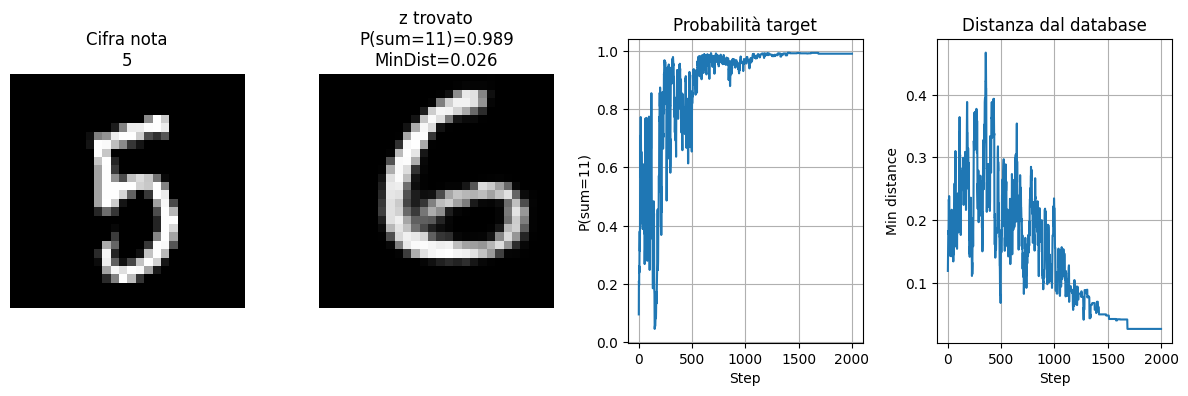

Rank 1 | Digit=6 | Similarity=0.9739
Rank 2 | Digit=6 | Similarity=0.9024
Rank 3 | Digit=6 | Similarity=0.9023
Rank 4 | Digit=6 | Similarity=0.9002
Rank 5 | Digit=6 | Similarity=0.8917
Rank 6 | Digit=6 | Similarity=0.8889
Rank 7 | Digit=6 | Similarity=0.8682
Rank 8 | Digit=6 | Similarity=0.8652


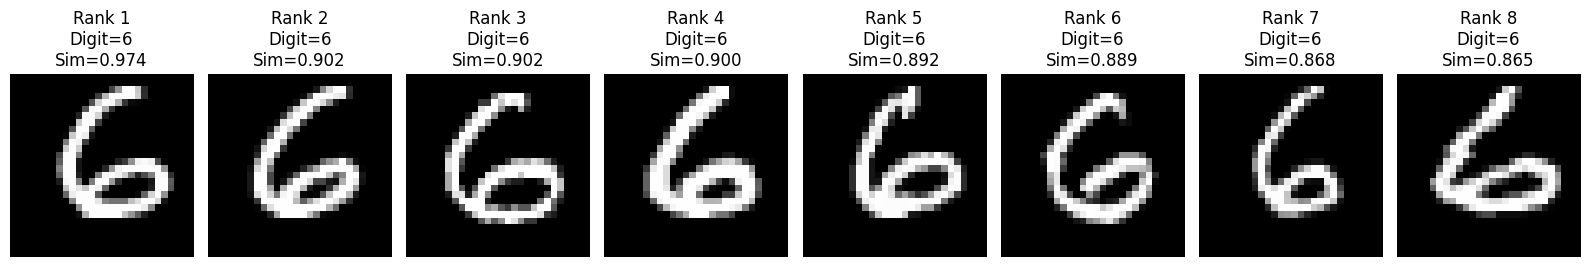

In [15]:

# Assicurati prima di avere già costruito il latent database:
# db_images, db_labels, db_latents = extract_latent_database(autoencoder, test_dataset, DEVICE)

known_image, known_label, known_idx = get_one_sample_of_digit(test_dataset, known_digit)

sa_result = simulated_annealing_search(
    autoencoder=autoencoder,
    sum_predictor=sum_predictor,
    known_image=known_image,
    target_sum=target_sum,
    latent_database=db_latents,
    latent_dim=LATENT_DIM,
    n_steps=2000,
    init_temp=1.0,
    final_temp=1e-4,
    step_std=0.05,
    spherical=True,
    lambda_reg=0.3,
    verbose=True
)

print("Known digit:", known_label)
print("Target sum:", target_sum)
print("Best probability for target sum:", sa_result["best_prob"])
print("Best energy:", sa_result["best_energy"])
print("Best min distance from latent database:", sa_result["best_dist"])

show_sa_result(
    known_image=known_image,
    known_digit=known_digit,
    target_sum=target_sum,
    sa_result=sa_result,
    autoencoder=autoencoder
)

neighbors = find_nearest_latent_neighbors(
    query_z=sa_result["best_z"],
    latent_database=db_latents,
    label_database=db_labels,
    image_database=db_images,
    top_k=8
)

for item in neighbors:
    print(
        f"Rank {item['rank']} | "
        f"Digit={item['label']} | "
        f"Similarity={item['similarity']:.4f}"
    )

show_nearest_neighbors(neighbors)
